# Week 9 Exercise: Sampling Distributions and the CLT

We will use 300 employee-survey responses as a finite teaching population. We know its mean, so we can check what repeated samples estimate.

Before each simulation: **predict → run → check → explain**. Record your predictions and interpretations in the Markdown cells. Most code is supplied; complete the two calculations marked `YOUR CODE` in Parts 4 and 5.

- **n**: people in one sample
- **B**: number of simulated samples; we store one mean per sample

Use the student notebook first. The worked solution is available for comparison afterward. The finite-population extension is optional. This exercise is ungraded and does not require a merge.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PURPLE = '#510C76'
TEAL = '#187D89'
GOLD = '#BA7D18'


In [2]:
# This small file is included beside the notebooks.
sat_survey = pd.read_csv('satisfaction_survey.txt', sep='\t')

# Check the supplied teaching population; do not silently drop responses.
assert len(sat_survey) == 300
assert sat_survey['satisfaction'].notna().all()
assert sat_survey['satisfaction'].between(1, 7).all()
print(f'Responses loaded: {len(sat_survey)}')


Responses loaded: 300


In [ ]:
sat_survey.head(10)

In [4]:
sat_survey.isna().sum()

employee_id     0
gender          3
location        5
tenure          2
satisfaction    0
dtype: int64

## Before the model: make a prediction

Imagine drawing 5 people at random from these responses and calculating their mean satisfaction. Then imagine drawing 100 people and calculating another mean.

If we repeated each process many times, where would the means cluster? Which process would give more variable means? Would the individual response scale change?

Treat the supplied records as the population for this exercise. They do not establish what every employee or every workplace would report.


**My prediction:**

<!-- BEGIN SOLUTION -->
Both collections of means should center near the mean of the supplied responses. Samples of 100 should give less variable averages than samples of 5. The original response scale does not change.
<!-- END SOLUTION -->

Now hold the number of people per sample fixed. Imagine increasing only the number of simulated samples, B.

Would this make an individual sample estimate more precise, or help us see its sampling distribution more clearly? Explain your prediction.


**My prediction about B:**

<!-- BEGIN SOLUTION -->
More repetitions should make the simulated sampling distribution more stable and our estimate of SE less noisy. They do not add information to an individual sample of n people.
<!-- END SOLUTION -->

## A model to compare with the simulation

For independent draws from the same population with finite variance, the sample mean centers on the population mean. For sufficiently large n, its sampling distribution is approximately normal. The adequacy of that approximation depends on the population and sampling design.

This is a claim about **sample means**, not a claim that the individual responses become normally distributed.

Our exercise samples without replacement from a finite population. The independent-draw standard-error formula is an approximation when n is small relative to N. We will inspect the discrepancy before an optional finite-population explanation.

## Part 1: Know Your Population

Calculate the population mean and standard deviation. 


In [5]:
population = sat_survey['satisfaction'].to_numpy()
N = len(population)
pop_mean = np.mean(population)
pop_std = np.std(population)

print(f'Population size (N): {N}')
print(f'Population mean (μ): {pop_mean:.4f}')
print(f'Population SD (σ):   {pop_std:.4f}')


Population size (N): 300
Population mean (μ): 3.9633
Population SD (σ):   1.0933


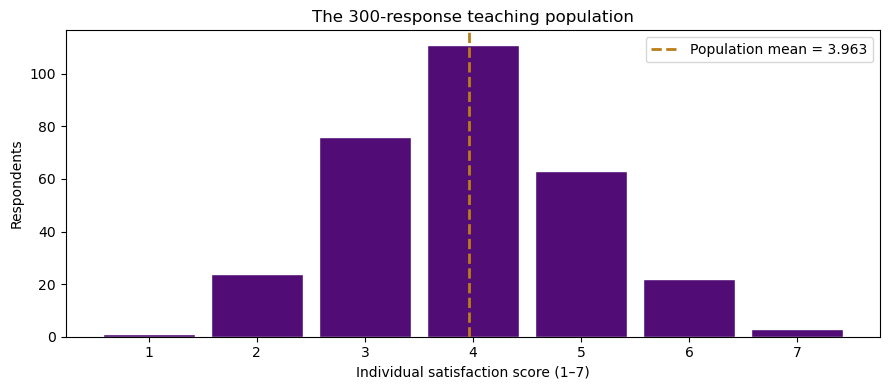

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(population, bins=np.arange(0.5, 8.5, 1), color=PURPLE,
        edgecolor='white', rwidth=0.85)
ax.axvline(pop_mean, color=GOLD, linestyle='--', linewidth=2,
           label=f'Population mean = {pop_mean:.3f}')
ax.set(xlabel='Individual satisfaction score (1–7)', ylabel='Respondents',
       title='The 300-response teaching population', xticks=range(1, 8))
ax.legend()
plt.tight_layout()
plt.show()


**Q1:** Describe the distribution of individual responses. Is it exactly normal? What can you say about these 300 responses, and what would require more information about how the survey was collected?

**My interpretation:** <!-- BEGIN SOLUTION -->
Scores are concentrated around 3–5, with the largest count at 4. This is a discrete, bounded distribution, not an exact normal distribution. These records describe the supplied responses; broader claims require information about recruitment, response, and the intended population.
<!-- END SOLUTION -->


## Part 2: One Sample, One Estimate

Before running the next cell, predict whether a sample of 30 people will have exactly the population mean.

We sample **without replacement within each sample**. Respondents can have the same satisfaction score, so repeated score values do not by themselves indicate repeated respondents.


In [7]:
n = 30
rng_one = np.random.default_rng(631)
sample = rng_one.choice(population, size=n, replace=False)
assert len(sample) == n
sample_mean = np.mean(sample)

print(f'People in the sample: {len(sample)}')
print(f'Sample mean:          {sample_mean:.4f}')
print(f'Population mean:      {pop_mean:.4f}')
print(f'Difference:           {sample_mean - pop_mean:.4f}')


People in the sample: 30
Sample mean:          3.8000
Population mean:      3.9633
Difference:           -0.1633


**Q2:** Compare the sample mean with the population mean. What would you expect from a new random sample? What happens if you rerun a cell that resets the same random seed?

**My interpretation:** <!-- BEGIN SOLUTION -->
With the fixed seed in this cell, the 30-person sample mean is 3.8000, compared with the teaching-population mean of approximately 3.9633. A new random sample can give another estimate. Rerunning a cell that resets the same seed reproduces the same draw; continuing a generator's state produces new draws.
<!-- END SOLUTION -->


## Part 3: Many Samples — The Sampling Distribution

One sample gives one estimate. We will simulate **B = 5,000** samples with **n = 30** people in each. Every repetition starts from the full 300-response population.

Before running: predict the center and spread of the resulting means. The loop below repeats the sampling and mean calculation from Part 2. Each pass stores one mean. Check the sample size inside the loop and the number of means afterward.


In [8]:
n = 30
B = 5_000
rng_many = np.random.default_rng(633)
sample_means = []
for b in range(B):
    sample = rng_many.choice(population, size=n, replace=False)
    assert len(sample) == n
    sample_mean = np.mean(sample)
    sample_means.append(sample_mean)

sample_means = np.array(sample_means)
assert len(sample_means) == B
assert np.isfinite(sample_means).all()
assert ((sample_means >= population.min()) & (sample_means <= population.max())).all()

print(f'People per sample (n): {n}')
print(f'Means stored (B):      {len(sample_means):,}')
print(f'Mean of means:         {sample_means.mean():.4f} (population μ = {pop_mean:.4f})')
print(f'SD of sample means:    {sample_means.std():.4f} (empirical SE)')


People per sample (n): 30
Means stored (B):      5,000
Mean of means:         3.9642 (population μ = 3.9633)
SD of sample means:    0.1912 (empirical SE)


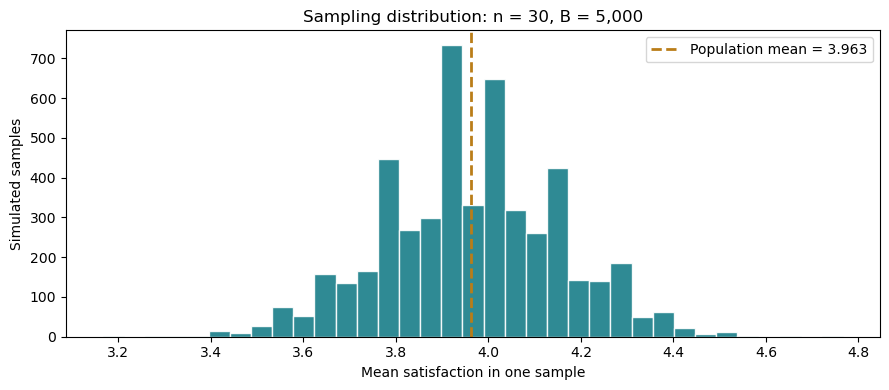

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(sample_means, bins=35, color=TEAL, edgecolor='white', alpha=0.9)
ax.axvline(pop_mean, color=GOLD, linestyle='--', linewidth=2,
           label=f'Population mean = {pop_mean:.3f}')
ax.set(xlabel='Mean satisfaction in one sample', ylabel='Simulated samples',
       title=f'Sampling distribution: n = {n}, B = {B:,}')
ax.legend()
plt.tight_layout()
plt.show()


**Q3:** What does one value in this histogram represent? Compare its center and spread with the individual-response histogram. Would increasing B change the underlying standard error, or the precision of our simulation of it?

**My interpretation:** <!-- BEGIN SOLUTION -->
One histogram value is the mean of 30 responses, not one person's score. The simulated means cluster near 3.9633 and vary less than individual responses. Increasing B improves the Monte Carlo approximation; it does not change the underlying sampling standard error for fixed n and sampling design.
<!-- END SOLUTION -->


## Part 4: How Sample Size Affects Precision

Compare n = 5, 10, 30, 50, and 100, keeping B = 5,000 fixed. Revisit your opening prediction before running.

Complete the one line marked `YOUR CODE`: calculate the standard deviation **of the simulated means**, not of the individual responses. 

We have used the same sampling steps once and in a loop. Now wrap the repeated steps in a function so we can reuse them for each sample size. The inputs name what can change: the population, n, B, and the random generator. The returned array contains B means. The checks are the same ones used above. We keep the simulated means for Part 5 so that the formula comparison uses these same results.


In [10]:
def draw_sample_means(population, n, B, rng):
    """Draw B samples, each of n records without replacement; store B means."""
    assert 1 <= n <= len(population)
    assert B >= 1
    means = np.empty(B)
    for b in range(B):
        sample = rng.choice(population, size=n, replace=False)
        assert len(sample) == n
        means[b] = sample.mean()
    assert len(means) == B
    assert np.isfinite(means).all()
    assert ((means >= population.min()) & (means <= population.max())).all()
    return means


# Check the function against the plain loop using the same seed.
function_check = draw_sample_means(population, 30, B, np.random.default_rng(633))
assert np.array_equal(function_check, sample_means)
print("The function reproduces the loop when the inputs and seed match.")

The function reproduces the loop when the inputs and seed match.


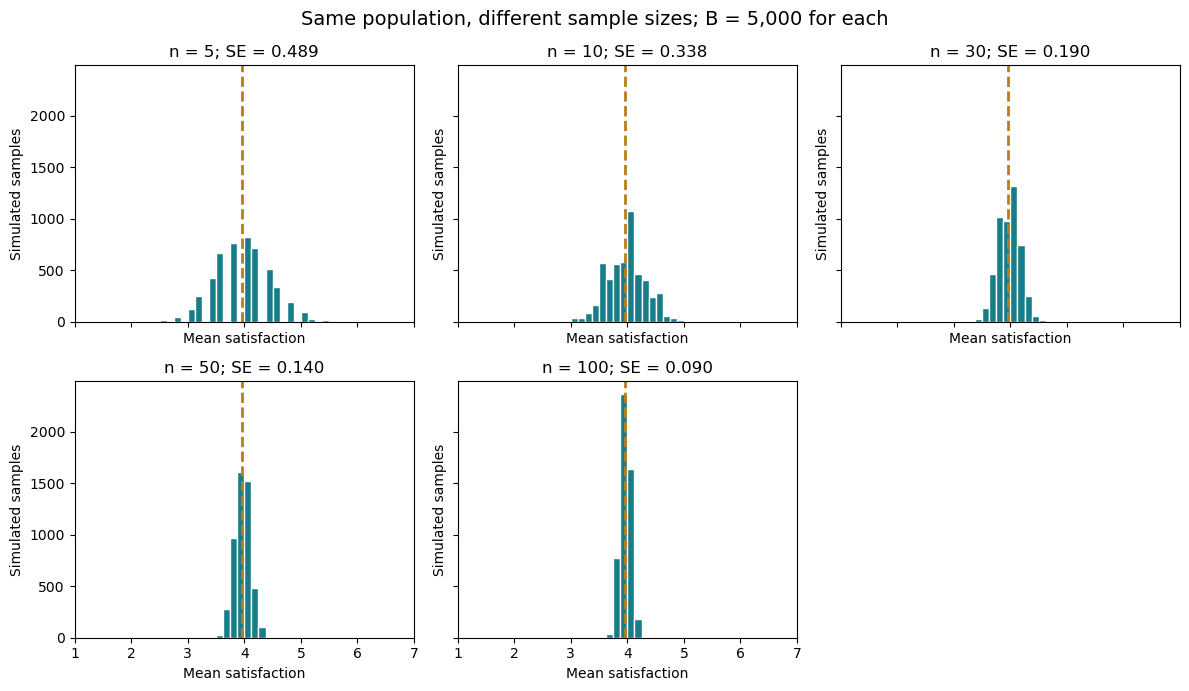

In [11]:
sample_sizes = [5, 10, 30, 50, 100]
B = 5_000
rng_sizes = np.random.default_rng(63109)
means_by_n = {}

fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
axes = axes.ravel()

for i, n in enumerate(sample_sizes):
    means = draw_sample_means(population, n, B, rng_sizes)
    means_by_n[n] = means

    emp_se = np.std(means)  # EXERCISE-BLANK: standard deviation of means
    assert emp_se is not None, 'Replace emp_se = None with the SD of the simulated means.'

    axes[i].hist(means, bins=np.linspace(1, 7, 49), color=TEAL, edgecolor='white')
    axes[i].axvline(pop_mean, color=GOLD, linestyle='--', linewidth=2)
    axes[i].set(title=f'n = {n}; SE = {emp_se:.3f}',
                xlabel='Mean satisfaction', ylabel='Simulated samples', xlim=(1, 7))

axes[-1].axis('off')
fig.suptitle(f'Same population, different sample sizes; B = {B:,} for each', fontsize=14)
plt.tight_layout()
plt.show()


**Q4:** What changes as n grows? What stays fixed? Compare the result with your prediction. Explain why the spread of individual responses and the spread of estimated means are different quantities.

**My interpretation:** <!-- BEGIN SOLUTION -->
The centers stay near the known population mean while spread decreases as n grows. The small-n distribution can remain visibly discrete; the CLT does not guarantee exact normality at every n. Individual-response variability is unchanged. Without-replacement sampling also reduces uncertainty as a sample uses a larger fraction of the finite population.
<!-- END SOLUTION -->


## Part 5: The Standard Error Formula

The standard error is the standard deviation of an estimate across repeated samples.

For independent draws with the same finite variance:

$$SE = \frac{\sigma}{\sqrt{n}}$$

Here σ describes individual-response variability, and n is the number of observations in one sample. B is not in this formula.

Our without-replacement samples from N = 300 have dependent draws. The formula above can approximate their SE when n/N is small. Compare it with the empirical SE; a discrepancy at larger sampling fractions is something to explain, not automatically a coding error.

Complete the theoretical-SE line below. Reuse the saved simulations from Part 4; do not generate a new distribution for this comparison.


In [12]:
results = []
for n in sample_sizes:
    means = means_by_n[n]
    assert len(means) == B
    emp_se = np.std(means, ddof=0)
    theo_se = pop_std / np.sqrt(n)  # EXERCISE-BLANK: population SD divided by the square root of n
    assert theo_se is not None, 'Replace theo_se = None with the independent-draw SE formula.'
    results.append({
        'n': n, 'Replicates': len(means), 'Mean of Means': means.mean(),
        'Empirical SE': emp_se, 'Independent-draw SE': theo_se
    })

df_se = pd.DataFrame(results)
print(df_se.to_string(index=False, float_format=lambda x: f'{x:.4f}'))


  n  Replicates  Mean of Means  Empirical SE  Independent-draw SE
  5        5000         3.9551        0.4887               0.4889
 10        5000         3.9694        0.3381               0.3457
 30        5000         3.9682        0.1896               0.1996
 50        5000         3.9638        0.1401               0.1546
100        5000         3.9643        0.0896               0.1093


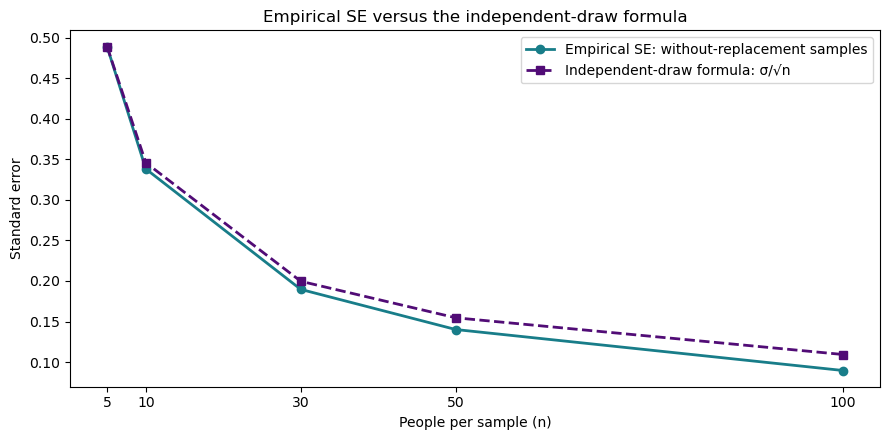

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(df_se['n'], df_se['Empirical SE'], 'o-', color=TEAL,
        linewidth=2, label='Empirical SE: without-replacement samples')
ax.plot(df_se['n'], df_se['Independent-draw SE'], 's--', color=PURPLE,
        linewidth=2, label='Independent-draw formula: σ/√n')
ax.set(xlabel='People per sample (n)', ylabel='Standard error',
       title='Empirical SE versus the independent-draw formula', xticks=sample_sizes)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()


**Q5:** How does the mismatch change as n grows relative to N = 300? What does the sampling rule suggest about why this happens? Does this mismatch mean that the CLT is false?

**My interpretation:** <!-- BEGIN SOLUTION -->
The independent-draw formula is close when n/N is small and increasingly overestimates SE as that fraction grows. At n=100, its SE is approximately 0.1093; the finite-population formula gives approximately 0.0894, close to the simulated result. The discrepancy reflects our without-replacement design, not a failure of the CLT. Remaining empirical differences come from Monte Carlo variation. A match need not improve monotonically with n when B is fixed.
<!-- END SOLUTION -->

Stop here for the core exercise. The finite-population explanation below is optional, and the worked solution provides an example interpretation.


## Optional: the finite-population correction

Sampling without replacement removes one possible source of variation: once a respondent is selected, that same record cannot appear again in that sample. When the sample is a large fraction of the finite population, its mean varies less than the independent-draw formula predicts.

For simple random samples without replacement, using population SD defined with `ddof=0`:

$$SE_{\mathrm{finite}} = \frac{\sigma}{\sqrt{n}}\sqrt{\frac{N-n}{N-1}}$$

Compare both models against the **same** simulated means. This extension explains the design effect; it is not an additional formula to memorize. At n = N, the sample contains every record and its mean has zero sampling variability. A normal approximation is a separate question.


  n  Replicates  Mean of Means  Empirical SE  Independent-draw SE  Finite-population SE
  5        5000         3.9551        0.4887               0.4889                0.4857
 10        5000         3.9694        0.3381               0.3457                0.3405
 30        5000         3.9682        0.1896               0.1996                0.1897
 50        5000         3.9638        0.1401               0.1546                0.1414
100        5000         3.9643        0.0896               0.1093                0.0894


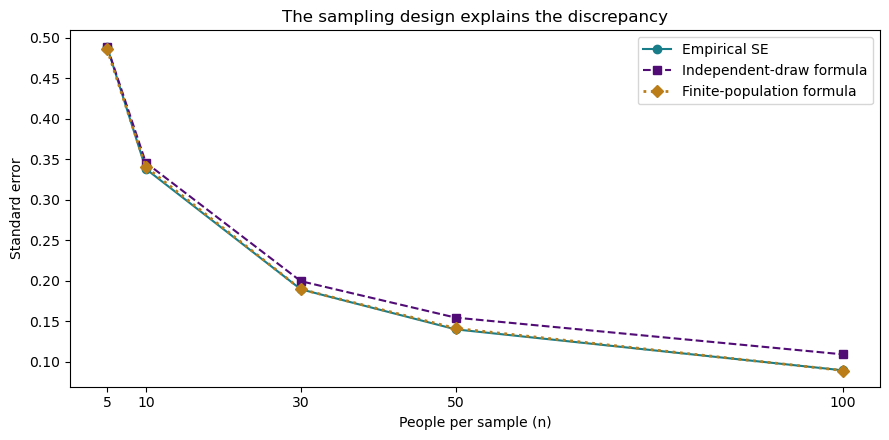

In [14]:
# Optional worked comparison: no new sampling is needed.
fpc_comparison = df_se.copy()
fpc_comparison['Finite-population SE'] = (
    pop_std / np.sqrt(fpc_comparison['n'])
    * np.sqrt((N - fpc_comparison['n']) / (N - 1))
)
print(fpc_comparison.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(df_se['n'], df_se['Empirical SE'], 'o-', color=TEAL, label='Empirical SE')
ax.plot(df_se['n'], df_se['Independent-draw SE'], 's--', color=PURPLE, label='Independent-draw formula')
ax.plot(fpc_comparison['n'], fpc_comparison['Finite-population SE'], 'D:',
        color=GOLD, linewidth=2, label='Finite-population formula')
ax.set(xlabel='People per sample (n)', ylabel='Standard error',
       title='The sampling design explains the discrepancy', xticks=sample_sizes)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()


### Optional alternate view: overlay the sampling distributions

Reuse the same means so that changes in the display are not mixed with changes in the simulation. The faceted plots are usually easier to read; this overlay is another way to compare spread.

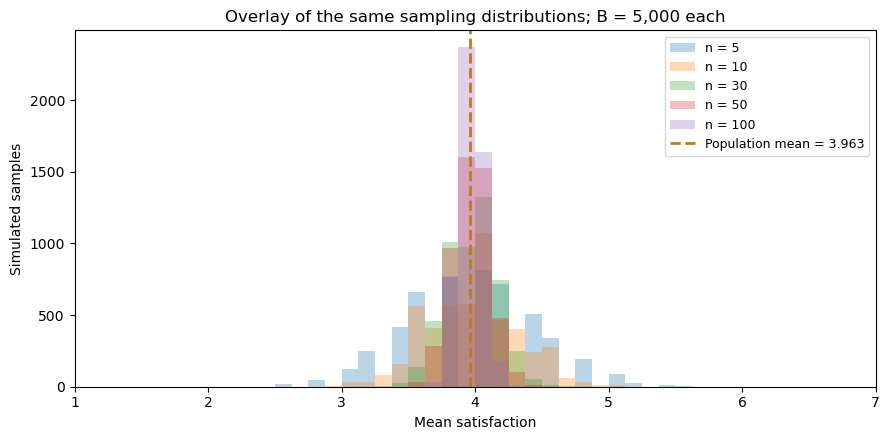

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for n in sample_sizes:
    ax.hist(means_by_n[n], bins=np.linspace(1, 7, 49), alpha=0.30, label=f'n = {n}')
ax.axvline(pop_mean, color=GOLD, linestyle='--', linewidth=2,
           label=f'Population mean = {pop_mean:.3f}')
ax.set(xlabel='Mean satisfaction', ylabel='Simulated samples', xlim=(1, 7),
       title=f'Overlay of the same sampling distributions; B = {B:,} each')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
